# Real Estate Investment Advisor
## Data Cleaning & Exploratory Data Analysis

**Dataset:** `data/india_housing_prices.csv`  
**Purpose:** validate, clean, engineer, and explore the supplied property listings.

> **Scope note:** This dataset has no verified resale prices, investment outcomes, crime rates, or infrastructure scores. Any investment label or future price created here is an assumption-based proxy, not observed performance.


## Contents

1. Imports and reproducible setup
2. Load and validate data
3. Data quality review and cleaning
4. Feature engineering
5. Exploratory analysis
6. Findings, limitations, and next steps

Run all cells in order. Outputs are saved to `data/processed/` and `reports/`.


### Setup A - Imports


In [272]:
# All imports required by this notebook are collected at the start.
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from IPython.display import display, Markdown
from plotly.subplots import make_subplots
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")


### Setup B - Project paths


In [273]:
# Find the project root whether run from the root or notebooks/ directory.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "data" / "india_housing_prices.csv").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from project root or notebooks/; dataset not found.")

DATA_PATH = PROJECT_ROOT / "data" / "india_housing_prices.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)


### Setup C - Analysis assumptions


In [274]:
# Assumptions for illustrative targets only; replace with validated outcomes.
REFERENCE_YEAR = 2026
ANNUAL_APPRECIATION_ASSUMPTION = 0.06
AGE_DEPRECIATION_PER_YEAR = 0.002
GOOD_INVESTMENT_THRESHOLD = 0.04
FORECAST_YEARS = 5
RANDOM_STATE = 42

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")


Project root: d:\Real Estate Investment Advisor Predicting Property Profitability & Future Value
Dataset: d:\Real Estate Investment Advisor Predicting Property Profitability & Future Value\data\india_housing_prices.csv


## 1. Load and validate the source data

Required-column validation makes schema changes visible before analysis.


In [275]:
EXPECTED_COLUMNS = ["ID", "State", "City", "Locality", "Property_Type", "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built", "Furnished_Status", "Floor_No", "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Public_Transport_Accessibility", "Parking_Space", "Security", "Amenities", "Facing", "Owner_Type", "Availability_Status"]
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df_raw.columns))
if missing_columns: raise ValueError(f"Missing required columns: {missing_columns}")
duplicate_mask = df_raw.duplicated()
exact_duplicates = int(duplicate_mask.sum())
duplicate_ids = int(df_raw["ID"].duplicated().sum())
print(f"Schema valid: {len(df_raw):,} rows x {df_raw.shape[1]} columns.")
print(f"Exact duplicate rows: {exact_duplicates:,} | Duplicate IDs: {duplicate_ids:,}")


Schema valid: 250,000 rows x 23 columns.
Exact duplicate rows: 0 | Duplicate IDs: 0


### Preview table



In [276]:
display(df_raw.head(10))


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move
5,6,West Bengal,Durgapur,Locality_246,Apartment,4,3500,135.28,0.04,2020,Semi-furnished,27,1,5,7,7,Low,Yes,Yes,"Playground, Clubhouse",West,Broker,Ready_to_Move
6,7,Tamil Nadu,Coimbatore,Locality_254,Independent House,3,4826,318.12,0.07,2016,Furnished,16,5,9,3,6,High,No,Yes,"Clubhouse, Garden, Playground",North,Builder,Under_Construction
7,8,Chhattisgarh,Bilaspur,Locality_490,Independent House,5,4252,141.39,0.03,2021,Unfurnished,24,4,4,10,10,High,Yes,Yes,"Gym, Pool, Clubhouse, Playground",North,Builder,Under_Construction
8,9,Delhi,New Delhi,Locality_232,Villa,4,2678,189.16,0.07,2003,Semi-furnished,23,16,22,7,5,Low,No,Yes,"Garden, Clubhouse, Playground",South,Broker,Under_Construction
9,10,Jharkhand,Ranchi,Locality_122,Villa,2,1393,187.42,0.13,2011,Unfurnished,6,13,14,3,3,High,Yes,No,"Clubhouse, Playground, Garden, Gym",East,Owner,Ready_to_Move


### Column profile table



In [277]:
schema = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "non_null": df_raw.notna().sum().values,
    "missing": df_raw.isna().sum().values,
    "missing_pct": df_raw.isna().mean().values * 100,
    "unique_values": df_raw.nunique(dropna=True).values,
})
display(schema.sort_values("missing_pct", ascending=False).reset_index(drop=True))


,column,dtype,non_null,missing,missing_pct,unique_values
0,ID,int64,250000,0,0.00,250000
1,State,object,250000,0,0.00,20
2,City,object,250000,0,0.00,42
3,Locality,object,250000,0,0.00,500
4,Property_Type,object,250000,0,0.00,3
5,BHK,int64,250000,0,0.00,5
6,Size_in_SqFt,int64,250000,0,0.00,4501
7,Price_in_Lakhs,float64,250000,0,0.00,48700
8,Price_per_SqFt,float64,250000,0,0.00,100
9,Year_Built,int64,250000,0,0.00,34


## 2. Data quality review and cleaning

**Decisions:** remove exact duplicates; trim text and standardize missing tokens; coerce expected numeric columns; exclude rows with missing or non-positive area/price from price analysis. Other missing values are retained for review. Imputation for modeling should be fitted on training data only.

Price per square foot is recomputed as price in lakhs multiplied by 100,000 and divided by area in square feet. Assuming the source price is in lakhs of INR, the result is INR per square foot.


### Cleaning transformations



In [278]:
df = df_raw.loc[~duplicate_mask].copy()
text_columns = df.select_dtypes(include=["object", "string"]).columns
missing_tokens = {"", "na", "n/a", "null", "none", "unknown"}
for column in text_columns:
    values = df[column].astype("string").str.strip()
    df[column] = values.mask(values.str.lower().isin(missing_tokens))
# Source price-per-sq-ft and age are recomputed below, so coerce only inputs.
numeric_columns = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Year_Built", "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals"]
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
rows_before_filter = len(df)
valid_price_area = df["Size_in_SqFt"].gt(0) & df["Price_in_Lakhs"].gt(0)
df = df.loc[valid_price_area].dropna(subset=["Size_in_SqFt", "Price_in_Lakhs"]).copy()
df["Price_per_SqFt"] = df["Price_in_Lakhs"] * 100_000 / df["Size_in_SqFt"]


### Cleaning summary table



In [279]:
quality_summary = pd.DataFrame({
    "measure": ["source rows", "exact duplicates removed", "rows removed for invalid price/area", "clean rows"],
    "count": [len(df_raw), exact_duplicates, rows_before_filter - len(df), len(df)],
})
display(quality_summary)


,measure,count
0,source rows,250000
1,exact duplicates removed,0
2,rows removed for invalid price/area,0
3,clean rows,250000


### Missing values table



In [280]:
missing_pct_all = df.isna().mean().mul(100)
missingness = missing_pct_all[missing_pct_all.gt(0)].sort_values(ascending=False)
display(missingness.rename("missing_pct").to_frame() if not missingness.empty else "No missing values remain.")


'No missing values remain.'

### Completeness by field after cleaning
 
 Each horizontal bar shows the share of cleaned listings with a value (teal) and without a value (coral). The chart is shown even when no missing values are found, so complete fields appear as 100% filled bars.


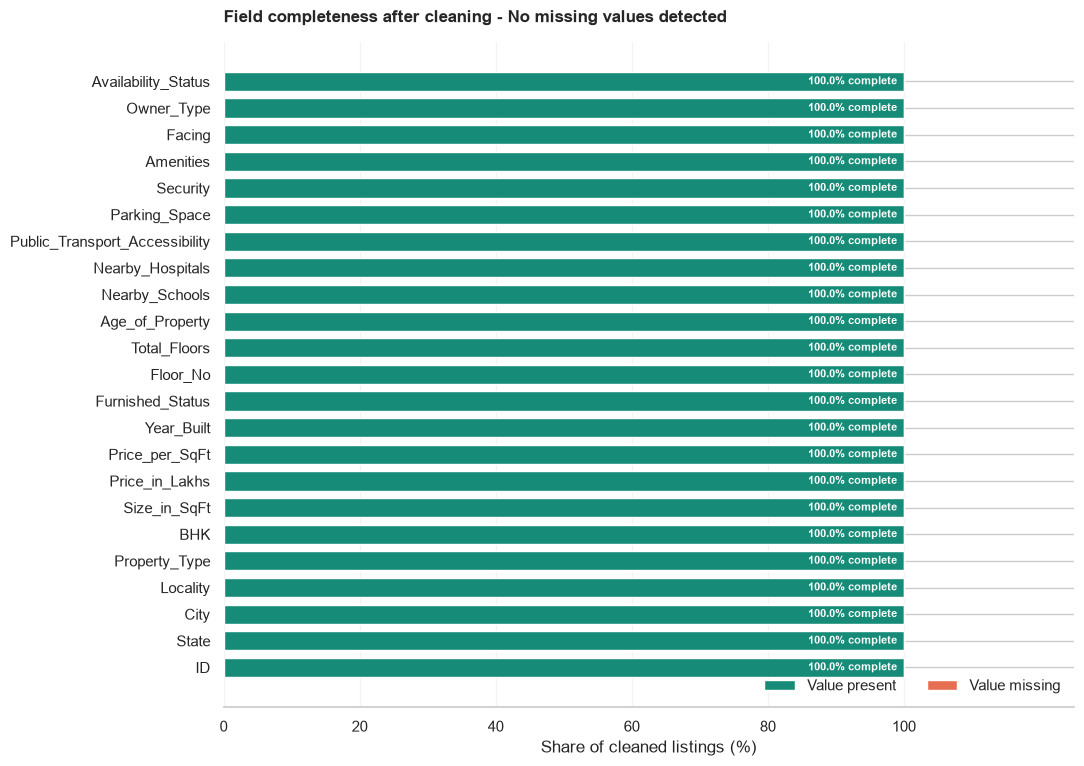

In [281]:
completeness_pct = 100 - missing_pct_all
field_order = missing_pct_all.sort_values().index
complete_values, missing_values = completeness_pct.loc[field_order], missing_pct_all.loc[field_order]
no_missing_values = bool(missing_values.eq(0).all())
title_note = "No missing values detected" if no_missing_values else "Complete and missing shares by field"
y = np.arange(len(field_order))
fig, ax = plt.subplots(figsize=(11, max(6, 0.34 * len(field_order))))
ax.barh(y, complete_values, color="#168C78", edgecolor="white", height=0.72, label="Value present")
ax.barh(y, missing_values, left=complete_values, color="#E76F51", edgecolor="white", height=0.72, label="Value missing")
ax.set_yticks(y)
ax.set_yticklabels(field_order)
ax.set_xlim(0, 125)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xlabel("Share of cleaned listings (%)")
ax.set_ylabel("")
ax.set_title(f"Field completeness after cleaning - {title_note}", loc="left", pad=14, weight="bold")
for row, (complete, missing) in enumerate(zip(complete_values, missing_values)):
    if complete >= 25:
        ax.text(complete - 1, row, f"{complete:.1f}% complete", ha="right", va="center", color="white", fontsize=8, weight="bold")
    else:
        ax.text(complete + 1, row, f"{complete:.1f}% complete", ha="left", va="center", color="#263238", fontsize=8)
    if missing > 0:
        ax.text(101, row, f"{missing:.1f}% missing", ha="left", va="center", color="#9C3D2E", fontsize=8, weight="bold")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, ncol=2)
plt.tight_layout()
plt.show()


## 3. Feature engineering

School and hospital scores below are counts per 1,000 sq ft of property area, not geographic neighborhood density. The proxy targets are optional workflow examples, **not observed outcomes**: the classification rule is driven by assumed appreciation and property age; the forecast compounds current asking price at an assumed rate.


### Feature engineering transformations



In [282]:
df["Age_of_Property"] = (REFERENCE_YEAR - df["Year_Built"]).clip(lower=0)
area_thousands = df["Size_in_SqFt"] / 1_000
df["School_Density_Score"] = df["Nearby_Schools"] / area_thousands
df["Hospital_Density_Score"] = df["Nearby_Hospitals"] / area_thousands
for column in ["Parking_Space", "Security"]:
    df[f"{column}_Binary"] = df[column].astype("string").str.lower().map({"yes": 1, "no": 0})
df["Annual_Appreciation_Proxy"] = ANNUAL_APPRECIATION_ASSUMPTION - df["Age_of_Property"] * AGE_DEPRECIATION_PER_YEAR
df["Good_Investment"] = (df["Annual_Appreciation_Proxy"] > GOOD_INVESTMENT_THRESHOLD).astype("Int64")
df["Price_After_5Y_Proxy"] = df["Price_in_Lakhs"] * (1 + ANNUAL_APPRECIATION_ASSUMPTION) ** FORECAST_YEARS
engineered = ["Price_per_SqFt", "Age_of_Property", "School_Density_Score", "Hospital_Density_Score", "Parking_Space_Binary", "Security_Binary", "Annual_Appreciation_Proxy", "Good_Investment", "Price_After_5Y_Proxy"]


### Engineered feature summary table



In [283]:
display(df[engineered].describe().T)


,count,mean,std,min,25%,50%,75%,max
Price_per_SqFt,"250,000.00","13,058.28","13,071.85",202.25,"4,802.84","9,244.75","15,987.39","99,182.00"
Age_of_Property,"250,000.00",19.48,9.81,3.00,11.00,19.00,28.00,36.00
School_Density_Score,"250,000.00",2.82,2.74,0.20,1.09,2.00,3.42,20.00
Hospital_Density_Score,"250,000.00",2.82,2.74,0.20,1.09,2.00,3.43,20.00
Parking_Space_Binary,"250,000.00",0.50,0.50,0.00,0.00,0.00,1.00,1.00
Security_Binary,"250,000.00",0.50,0.50,0.00,0.00,1.00,1.00,1.00
Annual_Appreciation_Proxy,"250,000.00",0.02,0.02,-0.01,0.00,0.02,0.04,0.05
Good_Investment,"250,000.00",0.21,0.40,0.00,0.00,0.00,0.00,1.00
Price_After_5Y_Proxy,"250,000.00",340.69,189.16,13.38,177.38,339.74,504.35,669.11


### Proxy label distribution table



In [284]:
display(df["Good_Investment"].value_counts(dropna=False).to_frame("count"))
print(f"Assumptions: {ANNUAL_APPRECIATION_ASSUMPTION:.1%} baseline; "
      f"{AGE_DEPRECIATION_PER_YEAR:.1%} age adjustment; "
      f"{GOOD_INVESTMENT_THRESHOLD:.1%} label threshold; {FORECAST_YEARS}-year scenario.")


,count
Good_Investment,
0,198456
1,51544


Assumptions: 6.0% baseline; 0.2% age adjustment; 4.0% label threshold; 5-year scenario.


## 4. Exploratory data analysis

### 4.1 Numeric distributions

The 99th percentile is used only as a chart display limit for readability; it does not remove observations from the cleaned data.


#### Distribution profile and outlier summary table


In [285]:
measure_columns = ["Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt"]
distribution_rows = []
for column in measure_columns:
    values = df[column].dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    distribution_rows.append({
        "measure": column,
        "n": len(values),
        "min": values.min(),
        "q1": q1,
        "median": values.median(),
        "mean": values.mean(),
        "q3": q3,
        "max": values.max(),
        "skewness": values.skew(),
        "IQR_outlier_count": int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()),
    })
distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.round(2))


,measure,n,min,q1,median,mean,q3,max,skewness,IQR_outlier_count
0,Size_in_SqFt,250000,500.00,"1,623.00","2,747.00","2,749.81","3,874.00","5,000.00",0.00,0
1,Price_in_Lakhs,250000,10.00,132.55,253.87,254.59,376.88,500.00,0.01,0
2,Price_per_SqFt,250000,202.25,"4,802.84","9,244.75","13,058.28","15,987.39","99,182.00",2.32,19723


#### Distribution charts - shape, spread, and skew


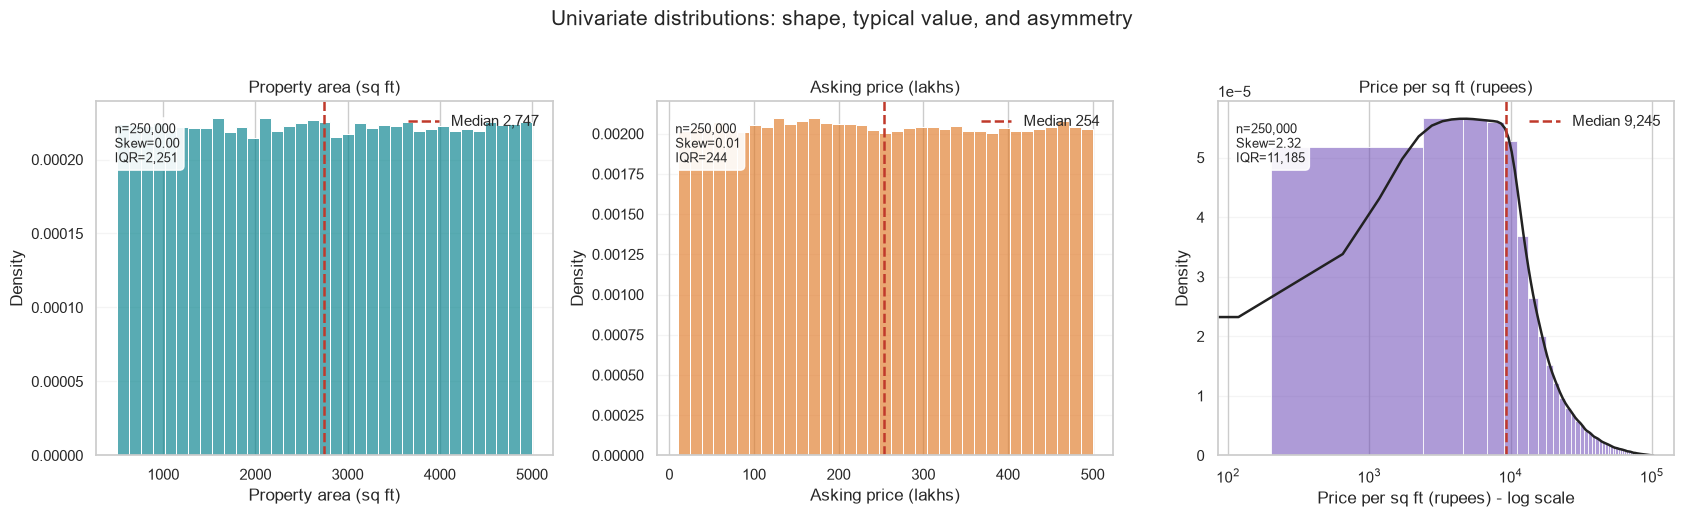

In [286]:
distribution_specs = [
    ("Size_in_SqFt", "Property area (sq ft)", "#007F8B", False),
    ("Price_in_Lakhs", "Asking price (lakhs)", "#E07A27", False),
    ("Price_per_SqFt", "Price per sq ft (rupees)", "#6C4AB6", True),
]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (column, title, color, log_axis) in zip(axes, distribution_specs):
    values = df[column].dropna()
    if log_axis:
        values = values[values > 0]
        sns.histplot(x=values, bins=45, stat="density", color=color,
                     alpha=.55, edgecolor="white", ax=ax)
        sns.kdeplot(x=values, color="#222222", linewidth=1.8, ax=ax)
        ax.set_xscale("log")
        ax.set_xlabel(f"{title} - log scale")
    else:
        sns.histplot(x=values, bins=35, stat="density", color=color,
                     alpha=.65, edgecolor="white", ax=ax)
        ax.set_xlabel(title)
    median = values.median()
    ax.axvline(median, color="#C0392B", linestyle="--", linewidth=1.8,
               label=f"Median {median:,.0f}")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(frameon=False, loc="best")
    ax.text(.04, .94,
            f"n={len(values):,}\nSkew={values.skew():.2f}\nIQR={values.quantile(.75)-values.quantile(.25):,.0f}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox={"boxstyle": "round,pad=.35", "facecolor": "white", "alpha": .9})
    ax.grid(axis="y", alpha=.2)
fig.suptitle("Univariate distributions: shape, typical value, and asymmetry", fontsize=15, y=1.03)
plt.tight_layout()
plt.show()


### 4.2 City comparison - coverage and asking-price differences

The source has no date field, so this is a cross-sectional city comparison, not a time trend. The chart reports each city median relative to the overall median. A Kruskal-Wallis test and epsilon-squared effect size quantify whether differences are large enough to matter; with a very large synthetic sample, p-values alone can exaggerate trivial differences.


#### City price summary table



In [287]:
city_summary = (
    df.dropna(subset=["City"])
      .groupby("City", as_index=False)
      .agg(
          listings=("ID", "count"),
          median_price_lakhs=("Price_in_Lakhs", "median"),
          q1_price_lakhs=("Price_in_Lakhs", lambda x: x.quantile(.25)),
          q3_price_lakhs=("Price_in_Lakhs", lambda x: x.quantile(.75)),
          median_price_per_sqft=("Price_per_SqFt", "median"),
          median_area_sqft=("Size_in_SqFt", "median"),
      )
)
city_summary["median_gap_lakhs"] = (
    city_summary["median_price_lakhs"] - df["Price_in_Lakhs"].median()
)
city_summary["median_gap_pct"] = (
    100 * city_summary["median_gap_lakhs"] / df["Price_in_Lakhs"].median()
)
display(city_summary.sort_values("median_price_lakhs", ascending=False).reset_index(drop=True))
city_summary.to_csv(REPORT_DIR / "city_price_summary.csv", index=False)


,City,listings,median_price_lakhs,q1_price_lakhs,q3_price_lakhs,median_price_per_sqft,median_area_sqft,median_gap_lakhs,median_gap_pct
0,Mysore,4217,259.52,136.74,376.85,"9,271.91","2,746.00",5.65,2.23
1,Pune,4224,258.93,134.55,375.10,"9,538.74","2,696.50",5.06,1.99
2,Kochi,6305,258.75,134.30,380.98,"9,280.63","2,790.00",4.88,1.92
3,Bangalore,4144,258.36,138.18,383.73,"9,344.15","2,747.00",4.49,1.77
4,Surat,6167,258.23,136.56,382.90,"9,479.57","2,729.00",4.36,1.72
5,Bhopal,6284,258.23,134.92,377.54,"9,236.16","2,743.50",4.36,1.72
6,Lucknow,6237,258.04,134.13,378.52,"9,441.21","2,749.00",4.17,1.64
7,Gaya,6170,257.20,132.99,383.35,"9,240.63","2,782.00",3.33,1.31
8,Dehradun,6234,257.03,136.91,379.05,"9,301.90","2,749.50",3.16,1.25
9,Chennai,6168,256.91,136.85,376.96,"9,328.56","2,764.50",3.04,1.20


#### City median deviations and statistical comparison


Kruskal-Wallis H=47.5, p=0.225, epsilon-squared=0.00003.


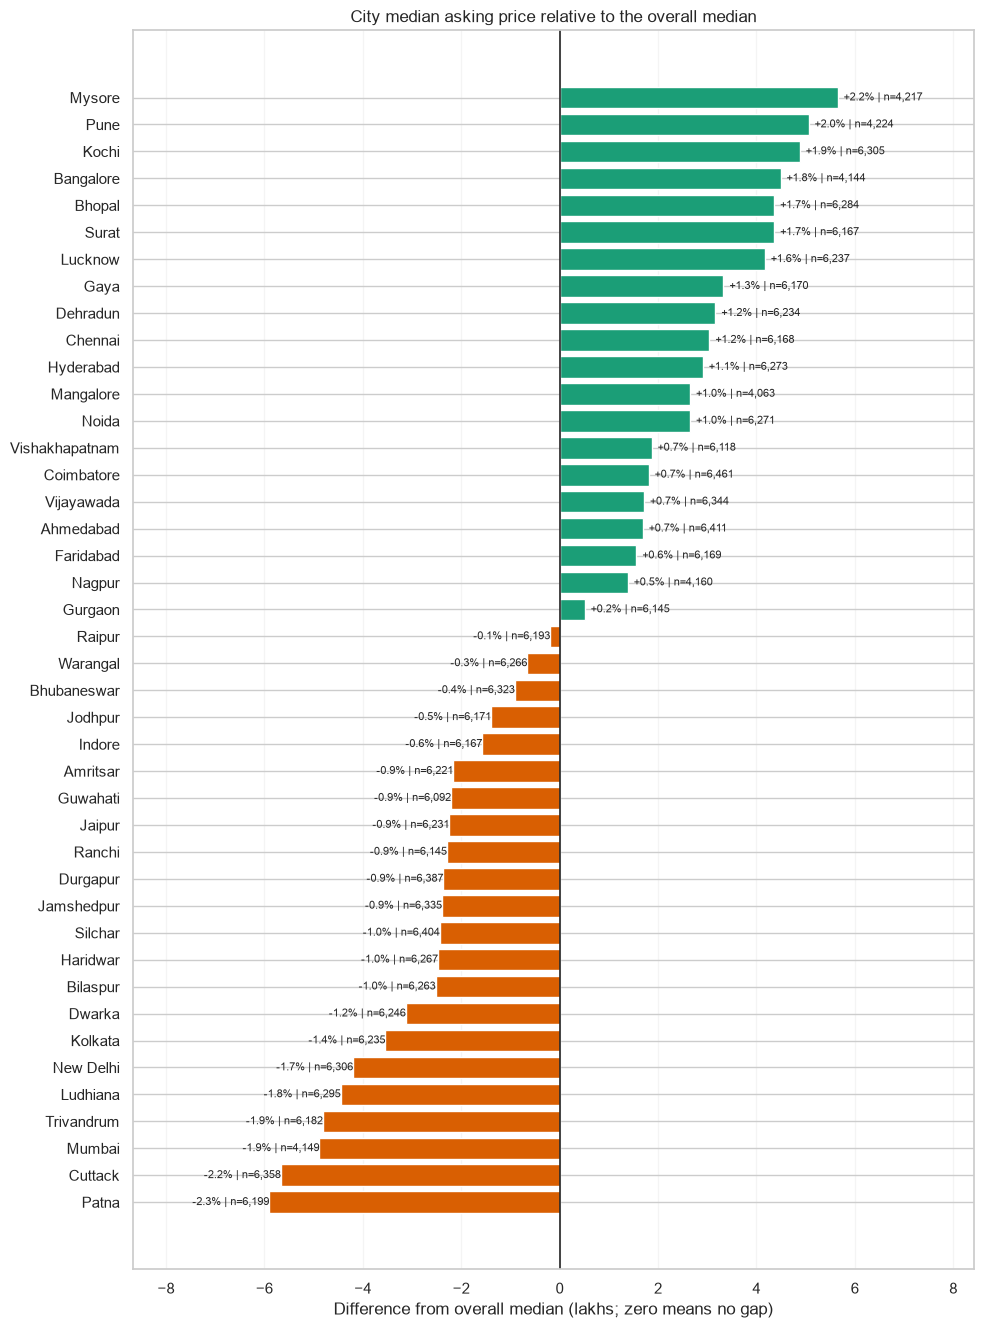

In [288]:
city_groups = [part["Price_in_Lakhs"].dropna().to_numpy()
               for _, part in df.groupby("City") if len(part) > 1]
kw_city = stats.kruskal(*city_groups)
n_city, k_city = len(df), len(city_groups)
epsilon_sq_city = max(0, (kw_city.statistic - k_city + 1) / (n_city - k_city))
print(f"Kruskal-Wallis H={kw_city.statistic:,.1f}, p={kw_city.pvalue:.3g}, "
      f"epsilon-squared={epsilon_sq_city:.5f}.")
plot_city = city_summary.sort_values("median_gap_lakhs")
colors = ["#D95F02" if value < 0 else "#1B9E77"
          for value in plot_city["median_gap_lakhs"]]
fig, ax = plt.subplots(figsize=(10, max(6, .32 * len(plot_city))))
y = np.arange(len(plot_city))
ax.barh(y, plot_city["median_gap_lakhs"], color=colors, edgecolor="white")
ax.axvline(0, color="#222222", linewidth=1.2)
ax.set_yticks(y)
ax.set_yticklabels(plot_city["City"])
ax.set(title="City median asking price relative to the overall median",
       xlabel="Difference from overall median (lakhs; zero means no gap)", ylabel="")
for yi, (_, row) in enumerate(plot_city.iterrows()):
    ax.text(row["median_gap_lakhs"], yi,
            f"  {row['median_gap_pct']:+.1f}% | n={int(row['listings']):,}",
            va="center", ha="left" if row["median_gap_lakhs"] >= 0 else "right",
            fontsize=8)
ax.grid(axis="x", alpha=.2)
ax.margins(x=.24)
plt.tight_layout()
plt.show()


### Geographic view - city price gaps and market context
 
 Each dot marks an approximate city center; the source has no property coordinates. The map uses a diverging color scale centered on the overall median, so teal indicates a city median above the overall median and coral indicates below. The panel ranks the five highest and lowest city medians. Hover over a marker for listing count and price-per-square-foot details.
 
 **Interpretation note:** the dots are intentionally a consistent size because listing counts are similar across cities in this synthetic dataset. The map is for geographic context, not neighborhood-level analysis.


In [289]:
# Approximate city-center coordinates (latitude, longitude); no parcel coordinates exist in the source.
city_coordinates = {
    "Ahmedabad": (23.0225, 72.5714), "Amritsar": (31.6340, 74.8723),
    "Bangalore": (12.9716, 77.5946), "Bhopal": (23.2599, 77.4126),
    "Bhubaneswar": (20.2961, 85.8245), "Bilaspur": (22.0797, 82.1409),
    "Chennai": (13.0827, 80.2707), "Coimbatore": (11.0168, 76.9558),
    "Cuttack": (20.4625, 85.8830), "Dehradun": (30.3165, 78.0322),
    "Durgapur": (23.5204, 87.3119), "Dwarka": (28.5921, 77.0460),
    "Faridabad": (28.4089, 77.3178), "Gaya": (24.7955, 84.9994),
    "Gurgaon": (28.4595, 77.0266), "Guwahati": (26.1445, 91.7362),
    "Haridwar": (29.9457, 78.1642), "Hyderabad": (17.3850, 78.4867),
    "Indore": (22.7196, 75.8577), "Jaipur": (26.9124, 75.7873),
    "Jamshedpur": (22.8046, 86.2029), "Jodhpur": (26.2389, 73.0243),
    "Kochi": (9.9312, 76.2673), "Kolkata": (22.5726, 88.3639),
    "Lucknow": (26.8467, 80.9462), "Ludhiana": (30.9010, 75.8573),
    "Mangalore": (12.9141, 74.8560), "Mumbai": (19.0760, 72.8777),
    "Mysore": (12.2958, 76.6394), "Nagpur": (21.1458, 79.0882),
    "New Delhi": (28.6139, 77.2090), "Noida": (28.5355, 77.3910),
    "Patna": (25.5941, 85.1376), "Pune": (18.5204, 73.8567),
    "Raipur": (21.2514, 81.6296), "Ranchi": (23.3441, 85.3096),
    "Silchar": (24.8333, 92.7789), "Surat": (21.1702, 72.8311),
    "Trivandrum": (8.5241, 76.9366), "Vijayawada": (16.5062, 80.6480),
    "Vishakhapatnam": (17.6868, 83.2185), "Warangal": (17.9689, 79.5941),
}

map_data = city_summary.copy()
map_data[["latitude", "longitude"]] = map_data["City"].apply(
    lambda city: pd.Series(city_coordinates.get(city, (np.nan, np.nan)))
)
map_data = map_data.dropna(subset=["latitude", "longitude"]).copy()
if map_data.empty:
    raise ValueError("No city coordinates matched the city summary.")

# Use a symmetric color range so positive and negative deviations are visually comparable.
color_limit = max(float(map_data["median_gap_pct"].abs().quantile(0.95)), 1.0)
top_bottom_cities = pd.concat([
    map_data.nsmallest(5, "median_gap_pct"),
    map_data.nlargest(5, "median_gap_pct"),
]).drop_duplicates("City").sort_values("median_gap_pct")
top_bottom_cities["gap_color"] = top_bottom_cities["median_gap_pct"].apply(
    lambda value: "#D66A5E" if value < 0 else "#168C78"
)

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "geo"}, {"type": "xy"}]],
    column_widths=[0.62, 0.38],
    horizontal_spacing=0.035,
    subplot_titles=("City locations", "Largest city price gaps"),
)
fig.add_trace(
    go.Scattergeo(
        lon=map_data["longitude"],
        lat=map_data["latitude"],
        text=map_data["City"],
        mode="markers",
        marker={
            "size": 12,
            "color": map_data["median_gap_pct"],
            "colorscale": [[0, "#D66A5E"], [0.5, "#F4F1E8"], [1, "#168C78"]],
            "cmin": -color_limit,
            "cmax": color_limit,
            "cmid": 0,
            "opacity": 0.92,
            "line": {"color": "white", "width": 1.2},
            "colorbar": {
                "title": {"text": "Price gap<br>vs overall median"},
                "ticksuffix": "%",
                "x": 0.605, "len": 0.72, "thickness": 13,
                "outlinewidth": 0,
            },
        },
        customdata=map_data[["listings", "median_price_lakhs", "median_price_per_sqft", "median_gap_pct"]],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "Listings: %{customdata[0]:,}<br>"
            "Median asking price: ₹%{customdata[1]:.1f} lakhs<br>"
            "Median price: ₹%{customdata[2]:,.0f} per sq ft<br>"
            "Gap vs overall median: %{customdata[3]:+.2f}%"
            "<extra></extra>"
        ),
        showlegend=False,
    ),
    row=1, col=1,
)
fig.add_trace(
    go.Bar(
        x=top_bottom_cities["median_gap_pct"],
        y=top_bottom_cities["City"],
        orientation="h",
        marker={"color": top_bottom_cities["gap_color"], "line": {"color": "white", "width": 0.8}},
        customdata=top_bottom_cities[["median_price_lakhs", "listings"]],
        text=[
            f"{gap:+.1f}%  |  ₹{price:.0f}L"
            for gap, price in zip(top_bottom_cities["median_gap_pct"], top_bottom_cities["median_price_lakhs"])
        ],
        textposition="outside",
        cliponaxis=False,
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Gap vs overall median: %{x:+.2f}%<br>"
            "Median asking price: ₹%{customdata[0]:.1f} lakhs<br>"
            "Listings: %{customdata[1]:,}"
            "<extra></extra>"
        ),
    ),
    row=1, col=2,
)
fig.update_geos(
    lataxis_range=[6, 36], lonaxis_range=[67, 98],
    showcountries=True, countrycolor="#AAB5C0",
    showland=True, landcolor="#F4F7FA",
    showocean=True, oceancolor="#EAF4FA",
    showcoastlines=True, coastlinecolor="#8293A3",
    showframe=False,
    domain={"x": [0, 0.62], "y": [0.02, 0.96]},
)
fig.update_xaxes(
    title_text="Difference from overall median (%)",
    ticksuffix="%",
    zeroline=True, zerolinecolor="#536273", zerolinewidth=1.3,
    showgrid=True, gridcolor="#E7EBEF",
    row=1, col=2,
)
fig.update_yaxes(
    title_text="",
    showgrid=False,
    categoryorder="array",
    categoryarray=top_bottom_cities["City"].tolist(),
    row=1, col=2,
)
fig.update_layout(
    title={
        "text": (
            "Indian property listings by city"
            "<br><sup>Map color shows median asking-price gap from the overall median; right panel ranks the five highest and lowest city medians.</sup>"
        ),
        "x": 0.04, "xanchor": "left",
        "font": {"size": 21, "color": "#243447"},
    },
    height=680,
    paper_bgcolor="white", plot_bgcolor="white",
    font={"family": "Arial, sans-serif", "color": "#334155", "size": 12},
    margin={"l": 20, "r": 95, "t": 105, "b": 45},
    bargap=0.32,
    hoverlabel={"bgcolor": "#172B4D", "font_size": 13, "font_color": "white"},
)
fig.show()


### 4.3 Area and asking price - relationship strength

A large hexbin plot turns a uniform dataset into a solid block and hides the takeaway. The left panel samples listings and adds a fitted trend; the right groups area into equal-frequency bands and plots mean price with a 95% confidence interval. Spearman correlation and sample size are reported on the chart. A flat trend means this file contains little evidence that larger listed area is associated with higher asking price.


#### Sample relationship and area-band confidence chart


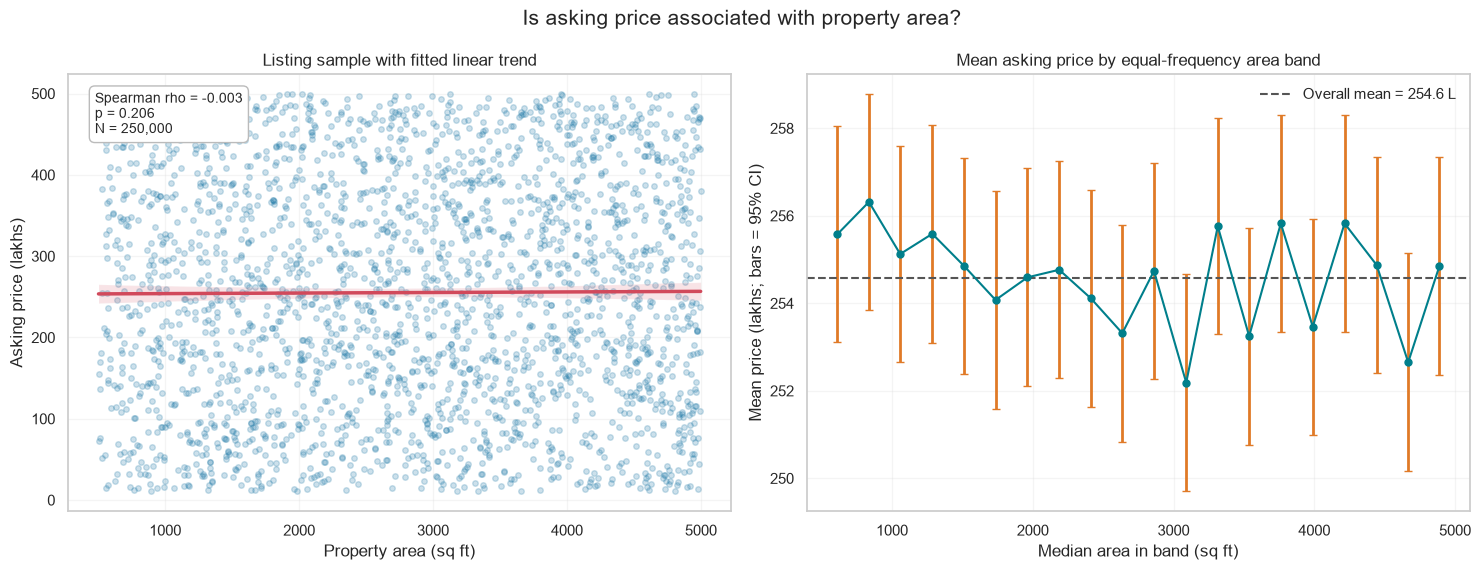

In [290]:
rho_area_price, p_area_price = stats.spearmanr(
    df["Size_in_SqFt"], df["Price_in_Lakhs"], nan_policy="omit"
)
sample = df.sample(min(2_500, len(df)), random_state=RANDOM_STATE)
area_bands = (
    df.assign(Area_Band=pd.qcut(df["Size_in_SqFt"], q=20, duplicates="drop"))
      .groupby("Area_Band", observed=True)
      .agg(
          n=("Price_in_Lakhs", "size"),
          median_area=("Size_in_SqFt", "median"),
          mean_price=("Price_in_Lakhs", "mean"),
          std_price=("Price_in_Lakhs", "std"),
      )
      .reset_index()
)
area_bands["ci95"] = 1.96 * area_bands["std_price"] / np.sqrt(area_bands["n"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
sns.regplot(
    data=sample, x="Size_in_SqFt", y="Price_in_Lakhs",
    scatter_kws={"s": 16, "alpha": .22, "color": "#1976A5"},
    line_kws={"color": "#D1495B", "linewidth": 2.5},
    ci=95, color="#D1495B", ax=axes[0],
)
axes[0].text(
    .04, .96,
    f"Spearman rho = {rho_area_price:.3f}\np = {p_area_price:.3g}\nN = {len(df):,}",
    transform=axes[0].transAxes, va="top", fontsize=10,
    bbox={"boxstyle": "round,pad=.4", "facecolor": "white", "edgecolor": "#BBBBBB"},
)
axes[0].set(
    title="Listing sample with fitted linear trend",
    xlabel="Property area (sq ft)",
    ylabel="Asking price (lakhs)",
)
axes[0].grid(alpha=.2)

axes[1].errorbar(
    area_bands["median_area"], area_bands["mean_price"],
    yerr=area_bands["ci95"], fmt="o-", color="#007F8B",
    ecolor="#E07A27", elinewidth=2, capsize=3, markersize=5,
)
axes[1].axhline(
    df["Price_in_Lakhs"].mean(), color="#555555", linestyle="--",
    linewidth=1.5, label=f"Overall mean = {df['Price_in_Lakhs'].mean():.1f} L",
)
axes[1].set(
    title="Mean asking price by equal-frequency area band",
    xlabel="Median area in band (sq ft)",
    ylabel="Mean price (lakhs; bars = 95% CI)",
)
axes[1].legend(frameon=False)
axes[1].grid(alpha=.2)
fig.suptitle("Is asking price associated with property area?", fontsize=15)
plt.tight_layout()
plt.show()


#### Area-band values table


In [291]:
display(area_bands[["Area_Band", "n", "median_area", "mean_price", "ci95"]].round(2))


,Area_Band,n,median_area,mean_price,ci95
0,"(499.999, 723.0]",12522,611.00,255.58,2.47
1,"(723.0, 947.0]",12481,836.00,256.32,2.47
2,"(947.0, 1172.0]",12502,"1,058.00",255.13,2.48
3,"(1172.0, 1398.0]",12505,"1,286.00",255.59,2.49
4,"(1398.0, 1623.0]",12550,"1,512.00",254.85,2.46
5,"(1623.0, 1848.0]",12480,"1,735.50",254.07,2.49
6,"(1848.0, 2076.0]",12473,"1,962.00",254.59,2.49
7,"(2076.0, 2300.0]",12504,"2,187.50",254.77,2.47
8,"(2300.0, 2524.0]",12531,"2,413.00",254.11,2.47
9,"(2524.0, 2747.0]",12486,"2,636.00",253.32,2.48


#### Area-band summary table


In [292]:
area_summary = (
    df.assign(Area_Band=pd.qcut(df["Size_in_SqFt"], q=10, duplicates="drop"))
      .groupby("Area_Band", observed=True)
      .agg(
          listings=("Price_in_Lakhs", "size"),
          median_area_sqft=("Size_in_SqFt", "median"),
          q1_price_lakhs=("Price_in_Lakhs", lambda x: x.quantile(.25)),
          median_price_lakhs=("Price_in_Lakhs", "median"),
          q3_price_lakhs=("Price_in_Lakhs", lambda x: x.quantile(.75)),
      )
      .reset_index()
)
area_summary["median_gap_lakhs"] = (
    area_summary["median_price_lakhs"] - df["Price_in_Lakhs"].median()
)
display(area_summary.round(2))


,Area_Band,listings,median_area_sqft,q1_price_lakhs,median_price_lakhs,q3_price_lakhs,median_gap_lakhs
0,"(499.999, 947.0]",25003,723.00,135.37,257.36,376.95,3.49
1,"(947.0, 1398.0]",25007,"1,173.00",132.57,254.17,378.67,0.30
2,"(1398.0, 1848.0]",25030,"1,623.00",131.95,254.60,376.87,0.73
3,"(1848.0, 2300.0]",24977,"2,077.00",133.14,254.71,376.79,0.84
4,"(2300.0, 2747.0]",25017,"2,524.00",131.00,252.78,376.15,-1.09
5,"(2747.0, 3201.0]",24989,"2,974.00",132.22,252.91,375.04,-0.96
6,"(3201.0, 3649.0]",25004,"3,426.00",132.97,252.34,376.70,-1.53
7,"(3649.0, 4100.0]",24974,"3,875.00",133.24,252.82,376.08,-1.06
8,"(4100.0, 4555.0]",25042,"4,328.00",133.26,253.69,378.70,-0.18
9,"(4555.0, 5000.0]",24957,"4,778.00",130.85,252.82,376.94,-1.05


#### Median asking-price gap across area bands


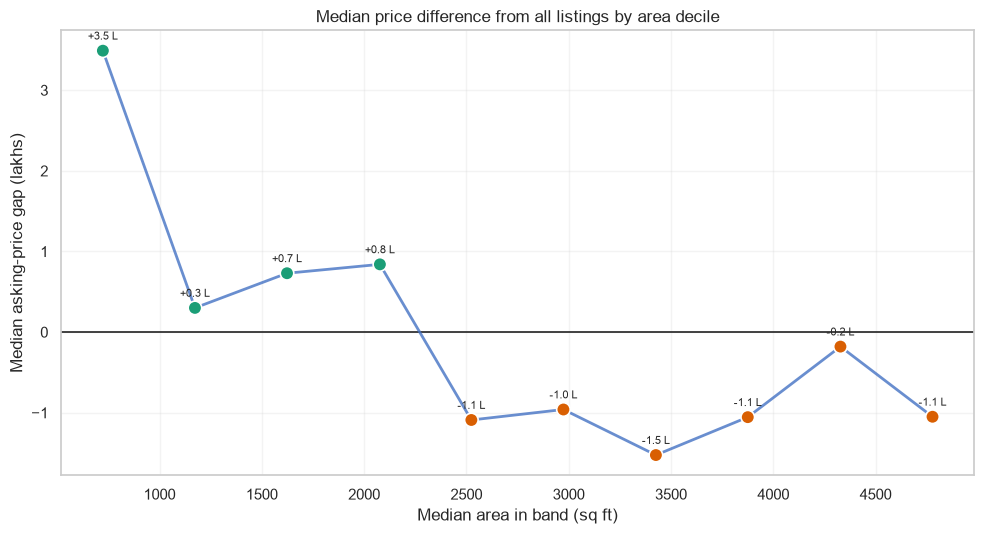

In [293]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#D95F02" if value < 0 else "#1B9E77"
          for value in area_summary["median_gap_lakhs"]]
ax.axhline(0, color="#222222", linewidth=1.2)
ax.plot(area_summary["median_area_sqft"], area_summary["median_gap_lakhs"],
        color="#4472C4", linewidth=2, alpha=.8)
ax.scatter(area_summary["median_area_sqft"], area_summary["median_gap_lakhs"],
           c=colors, s=95, edgecolor="white", linewidth=1.2, zorder=3)
for row in area_summary.itertuples():
    ax.annotate(f"{row.median_gap_lakhs:+.1f} L", 
                (row.median_area_sqft, row.median_gap_lakhs),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax.set(title="Median price difference from all listings by area decile",
       xlabel="Median area in band (sq ft)",
       ylabel="Median asking-price gap (lakhs)")
ax.grid(alpha=.22)
plt.tight_layout()
plt.show()


### 4.4 Property type and bedroom segments

Compare asking price and price per square foot across property-type and BHK combinations. Cell counts are shown so sparse combinations can be identified rather than over-interpreted.


#### Segment summary table and group test


In [294]:
segment_summary = (
    df.dropna(subset=["Property_Type", "BHK"])
      .groupby(["Property_Type", "BHK"], as_index=False)
      .agg(
          listings=("ID", "size"),
          median_area_sqft=("Size_in_SqFt", "median"),
          median_price_lakhs=("Price_in_Lakhs", "median"),
          median_price_per_sqft=("Price_per_SqFt", "median"),
      )
)
display(segment_summary.sort_values(["Property_Type", "BHK"]).round(2))

type_groups = [g["Price_in_Lakhs"].dropna().to_numpy()
               for _, g in df.groupby("Property_Type") if len(g) > 1]
bhk_groups = [g["Price_in_Lakhs"].dropna().to_numpy()
              for _, g in df.groupby("BHK") if len(g) > 1]
test_rows = []
for dimension, groups in [("Property_Type", type_groups), ("BHK", bhk_groups)]:
    result = stats.kruskal(*groups)
    n, k = sum(map(len, groups)), len(groups)
    effect = max(0, (result.statistic - k + 1) / (n - k))
    test_rows.append({
        "grouping": dimension, "groups": k, "n": n,
        "kruskal_H": result.statistic, "p_value": result.pvalue,
        "epsilon_squared": effect,
    })
segment_tests = pd.DataFrame(test_rows)
display(segment_tests.round(6))


,Property_Type,BHK,listings,median_area_sqft,median_price_lakhs,median_price_per_sqft
0,Apartment,1,16651,"2,747.00",255.13,"9,332.80"
1,Apartment,2,16450,"2,724.50",252.10,"9,212.88"
2,Apartment,3,16575,"2,753.00",253.91,"9,240.80"
3,Apartment,4,16662,"2,768.00",255.28,"9,206.85"
4,Apartment,5,16618,"2,748.00",253.10,"9,242.38"
5,Independent House,1,16613,"2,721.00",255.27,"9,333.68"
6,Independent House,2,16649,"2,741.00",254.05,"9,328.87"
7,Independent House,3,16701,"2,761.00",254.55,"9,270.42"
8,Independent House,4,16524,"2,752.00",256.58,"9,242.56"
9,Independent House,5,16813,"2,727.00",254.29,"9,345.08"


,grouping,groups,n,kruskal_H,p_value,epsilon_squared
0,Property_Type,3,250000,5.40,0.07,0.00
1,BHK,5,250000,1.14,0.89,0.00


#### Median price per sq ft by property type and BHK


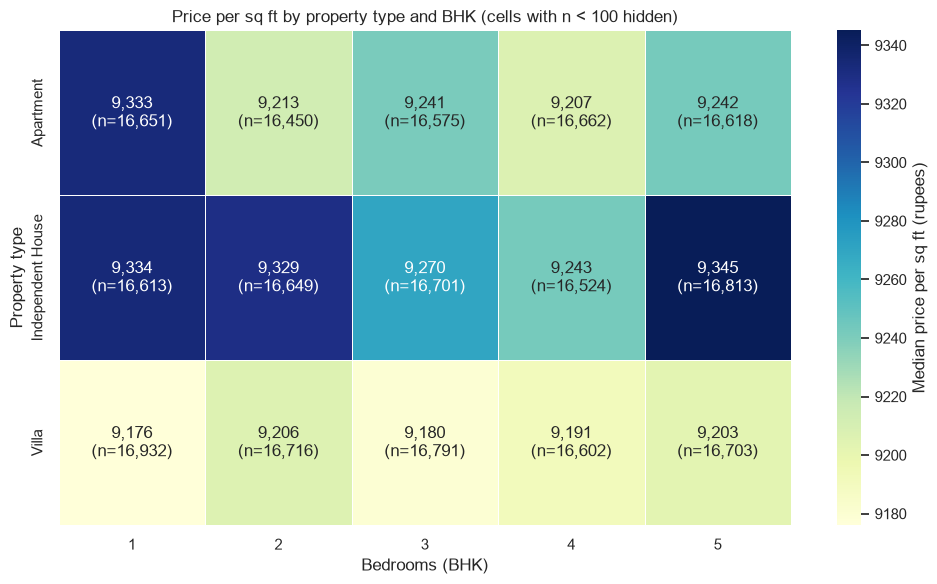

In [295]:
segment_wide = segment_summary.pivot(
    index="Property_Type", columns="BHK", values="median_price_per_sqft"
)
counts_wide = segment_summary.pivot(
    index="Property_Type", columns="BHK", values="listings"
)
annotations = segment_wide.copy().astype(object)
for row_name in segment_wide.index:
    for col_name in segment_wide.columns:
        value = segment_wide.loc[row_name, col_name]
        count = counts_wide.loc[row_name, col_name]
        annotations.loc[row_name, col_name] = (
            "" if pd.isna(value) or count < 100
            else f"{value:,.0f}\n(n={count:,.0f})"
        )
plot_values = segment_wide.where(counts_wide >= 100)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(plot_values, annot=annotations, fmt="", cmap="YlGnBu",
            linewidths=.6, linecolor="white",
            cbar_kws={"label": "Median price per sq ft (rupees)"}, ax=ax)
ax.set(title="Price per sq ft by property type and BHK (cells with n < 100 hidden)",
       xlabel="Bedrooms (BHK)", ylabel="Property type")
plt.tight_layout()
plt.show()


### 4.5 Nearby schools and hospitals

Nearby amenity counts are listing attributes, not geographic accessibility or quality scores. The analysis reports rank association and groups counts for a descriptive comparison; it does not imply an amenity causes a price change.


#### Amenity-price association table


In [296]:
amenity_results = []
for feature in ["Nearby_Schools", "Nearby_Hospitals"]:
    valid = df[[feature, "Price_in_Lakhs", "Price_per_SqFt"]].dropna()
    rho_price, p_price = stats.spearmanr(valid[feature], valid["Price_in_Lakhs"])
    rho_ppsf, p_ppsf = stats.spearmanr(valid[feature], valid["Price_per_SqFt"])
    amenity_results.append({
        "amenity_count": feature,
        "n": len(valid),
        "spearman_rho_vs_price": rho_price,
        "p_value_vs_price": p_price,
        "spearman_rho_vs_price_per_sqft": rho_ppsf,
        "p_value_vs_price_per_sqft": p_ppsf,
    })
amenity_association = pd.DataFrame(amenity_results)
display(amenity_association.round(5))


,amenity_count,n,spearman_rho_vs_price,p_value_vs_price,spearman_rho_vs_price_per_sqft,p_value_vs_price_per_sqft
0,Nearby_Schools,250000,0.00,0.94,-0.00,0.26
1,Nearby_Hospitals,250000,-0.00,0.17,-0.00,0.39


#### Asking price by amenity count


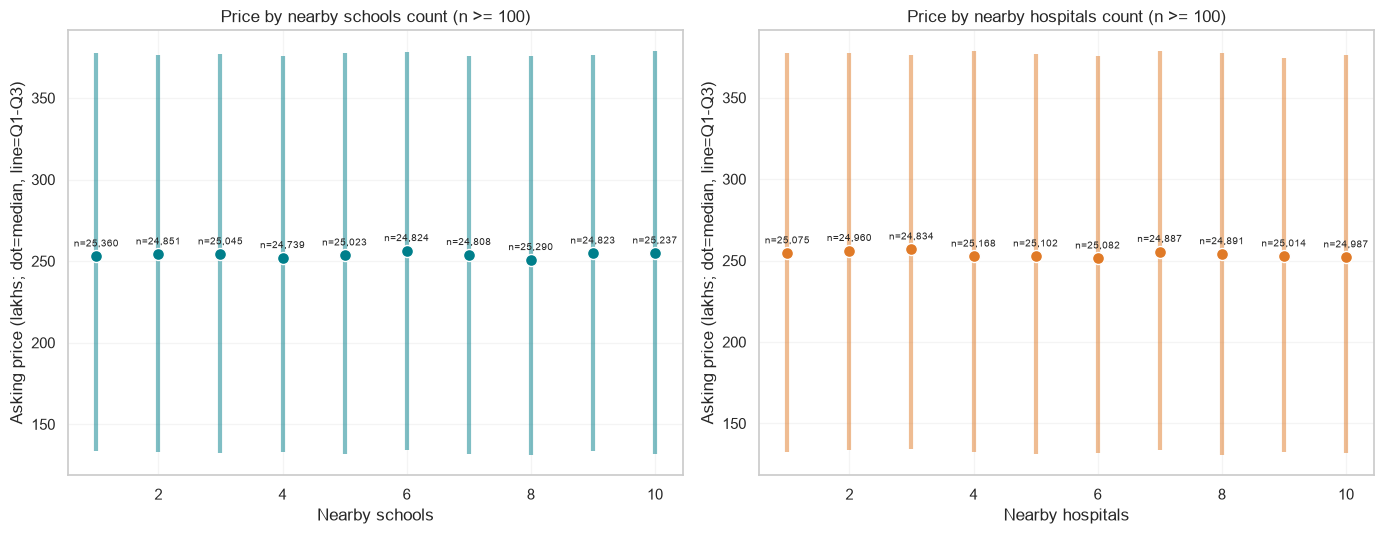

In [297]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, feature, color, label in zip(
    axes,
    ["Nearby_Schools", "Nearby_Hospitals"],
    ["#007F8B", "#E07A27"],
    ["Nearby schools", "Nearby hospitals"],
):
    grouped = (
        df.groupby(feature, dropna=True)
          .agg(n=("Price_in_Lakhs", "size"),
               median_price=("Price_in_Lakhs", "median"),
               q1=("Price_in_Lakhs", lambda x: x.quantile(.25)),
               q3=("Price_in_Lakhs", lambda x: x.quantile(.75)))
          .query("n >= 100")
          .reset_index()
    )
    ax.vlines(grouped[feature], grouped["q1"], grouped["q3"],
              color=color, alpha=.5, linewidth=3)
    ax.scatter(grouped[feature], grouped["median_price"], color=color,
               edgecolor="white", s=75, zorder=3)
    for row in grouped.itertuples():
        ax.annotate(f"n={row.n:,}", (getattr(row, feature), row.median_price),
                    xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7)
    ax.set(title=f"Price by {label.lower()} count (n >= 100)",
           xlabel=label, ylabel="Asking price (lakhs; dot=median, line=Q1-Q3)")
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()


### 4.6 Security field coverage (crime rate is not supplied)

The dataset has a security listing attribute but no crime-rate measure. This is a data-coverage chart only; it does not estimate crime impact or investment quality.


#### Security category coverage table


In [298]:
security_summary = (
    df["Security"].fillna("Missing")
      .value_counts(dropna=False)
      .rename_axis("security_value")
      .rename("listings")
      .reset_index()
)
security_summary["share"] = security_summary["listings"] / security_summary["listings"].sum()
display(security_summary)


,security_value,listings,share
0,Yes,125233,0.50
1,No,124767,0.50


#### Security category coverage chart


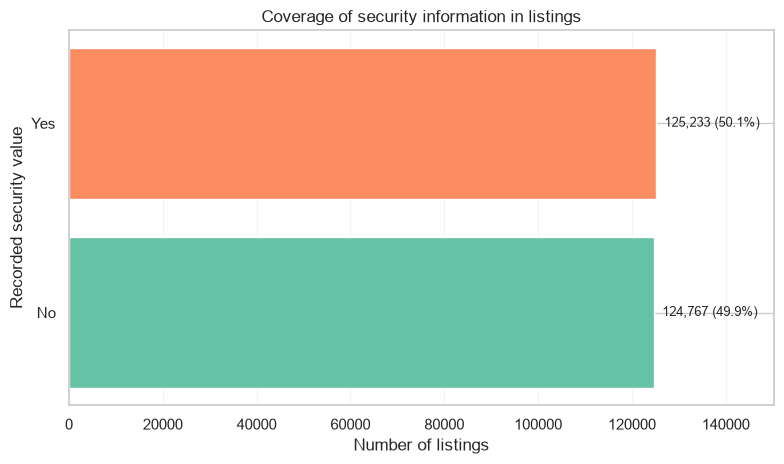

In [299]:
plot_security = security_summary.sort_values("listings")
fig, ax = plt.subplots(figsize=(8, 4.8))
palette = sns.color_palette("Set2", n_colors=len(plot_security))
bars = ax.barh(plot_security["security_value"], plot_security["listings"],
               color=palette, edgecolor="white")
for bar, (_, row) in zip(bars, plot_security.iterrows()):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
            f"  {int(row['listings']):,} ({row['share']:.1%})",
            va="center", fontsize=9)
ax.set(title="Coverage of security information in listings",
       xlabel="Number of listings", ylabel="Recorded security value")
ax.grid(axis="x", alpha=.2)
ax.margins(x=.2)
plt.tight_layout()
plt.show()


### 4.7 Numeric feature relationships

Pearson correlation captures linear association; Spearman captures rank association. Both are descriptive. Correlation involving engineered ratios or the appreciation proxy can be mechanical by construction.


#### Correlation matrix table


In [300]:
corr_cols = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals",
    "School_Density_Score", "Hospital_Density_Score",
    "Annual_Appreciation_Proxy",
]
corr = df[corr_cols].corr(numeric_only=True)
display(corr.round(3))
corr.to_csv(REPORT_DIR / "correlation_matrix.csv")


,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Age_of_Property,Nearby_Schools,Nearby_Hospitals,School_Density_Score,Hospital_Density_Score,Annual_Appreciation_Proxy
BHK,1.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,0.00
Size_in_SqFt,-0.00,1.00,-0.00,-0.61,-0.00,0.00,-0.00,-0.63,-0.63,0.00
Price_in_Lakhs,-0.00,-0.00,1.00,0.56,-0.00,0.00,-0.00,0.00,0.00,0.00
Price_per_SqFt,0.00,-0.61,0.56,1.00,0.00,-0.00,-0.00,0.55,0.55,-0.00
Age_of_Property,-0.00,-0.00,-0.00,0.00,1.00,0.00,0.00,0.00,0.00,-1.00
Nearby_Schools,-0.00,0.00,0.00,-0.00,0.00,1.00,-0.00,0.54,-0.00,-0.00
Nearby_Hospitals,0.00,-0.00,-0.00,-0.00,0.00,-0.00,1.00,-0.00,0.54,-0.00
School_Density_Score,0.00,-0.63,0.00,0.55,0.00,0.54,-0.00,1.00,0.56,-0.00
Hospital_Density_Score,0.00,-0.63,0.00,0.55,0.00,-0.00,0.54,0.56,1.00,-0.00
Annual_Appreciation_Proxy,0.00,0.00,0.00,-0.00,-1.00,-0.00,-0.00,-0.00,-0.00,1.00


#### Correlation heatmap


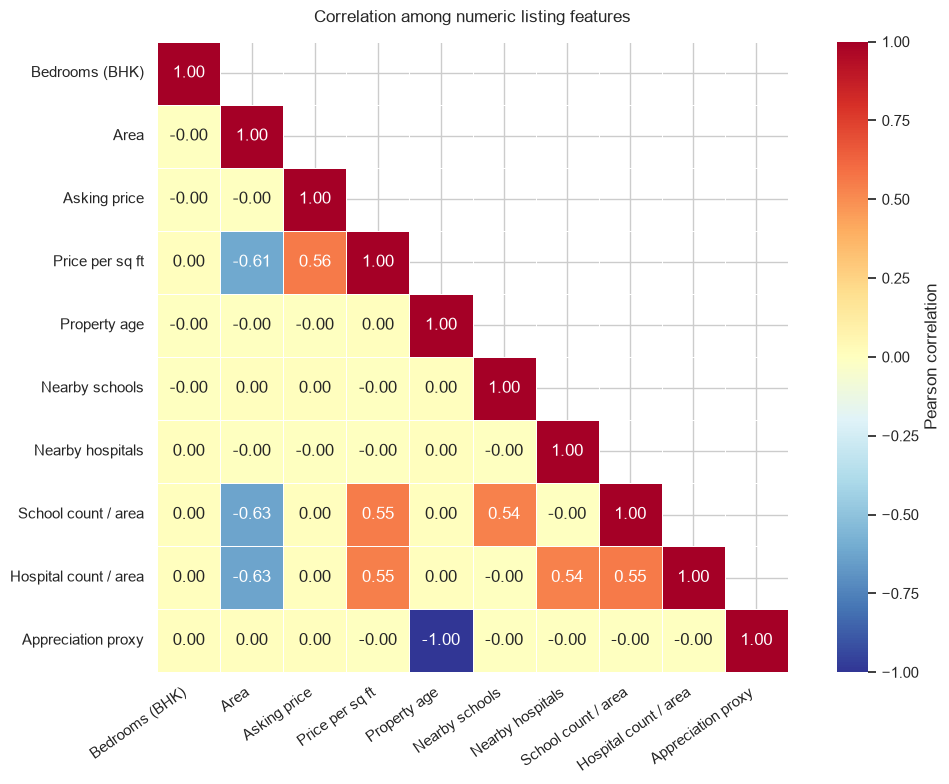

In [301]:
corr_labels = {
    "BHK": "Bedrooms (BHK)",
    "Size_in_SqFt": "Area",
    "Price_in_Lakhs": "Asking price",
    "Price_per_SqFt": "Price per sq ft",
    "Age_of_Property": "Property age",
    "Nearby_Schools": "Nearby schools",
    "Nearby_Hospitals": "Nearby hospitals",
    "School_Density_Score": "School count / area",
    "Hospital_Density_Score": "Hospital count / area",
    "Annual_Appreciation_Proxy": "Appreciation proxy",
}
corr_plot = corr.rename(index=corr_labels, columns=corr_labels)
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_plot, mask=mask, cmap="RdYlBu_r", center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", square=True,
            linewidths=.7, linecolor="white",
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation among numeric listing features", pad=14)
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Data-driven EDA summary

This summary converts the main tests into plain-language checks. Treat effect sizes as more useful than p-values when the dataset contains many rows.


### EDA evidence table


In [302]:
max_city_gap_pct = city_summary["median_gap_pct"].abs().max()
area_band_median_range = (
    area_summary["median_price_lakhs"].max()
    - area_summary["median_price_lakhs"].min()
)
property_type_effect = segment_tests.loc[
    segment_tests["grouping"] == "Property_Type", "epsilon_squared"
].iloc[0]
bhk_effect = segment_tests.loc[
    segment_tests["grouping"] == "BHK", "epsilon_squared"
].iloc[0]
diagnostics = pd.DataFrame([
    {
        "question": "Does area track asking price?",
        "measure": "Spearman rho",
        "estimate": rho_area_price,
        "p_value": p_area_price,
        "context": "Near 0 means weak monotonic association.",
    },
    {
        "question": "How large are city price differences?",
        "measure": "Kruskal epsilon-squared",
        "estimate": epsilon_sq_city,
        "p_value": kw_city.pvalue,
        "context": f"Largest city median gap is {max_city_gap_pct:.2f}% from overall median.",
    },
    {
        "question": "Do property types differ in asking price?",
        "measure": "Kruskal epsilon-squared",
        "estimate": property_type_effect,
        "p_value": segment_tests.loc[segment_tests["grouping"] == "Property_Type", "p_value"].iloc[0],
        "context": "Small effect size means little practical separation.",
    },
    {
        "question": "Do BHK groups differ in asking price?",
        "measure": "Kruskal epsilon-squared",
        "estimate": bhk_effect,
        "p_value": segment_tests.loc[segment_tests["grouping"] == "BHK", "p_value"].iloc[0],
        "context": "Compare effect size with the segment counts.",
    },
    {
        "question": "Do amenity counts track price per sq ft?",
        "measure": "Spearman rho: schools / hospitals",
        "estimate": (
            amenity_association["spearman_rho_vs_price_per_sqft"].iloc[0],
            amenity_association["spearman_rho_vs_price_per_sqft"].iloc[1],
        ),
        "p_value": (
            amenity_association["p_value_vs_price_per_sqft"].iloc[0],
            amenity_association["p_value_vs_price_per_sqft"].iloc[1],
        ),
        "context": "Reported in school-count, hospital-count order.",
    },
])
display(diagnostics)


,question,measure,estimate,p_value,context
0,Does area track asking price?,Spearman rho,-0.00,0.21,Near 0 means weak monotonic association.
1,How large are city price differences?,Kruskal epsilon-squared,0.00,0.23,Largest city median gap is 2.32% from overall ...
2,Do property types differ in asking price?,Kruskal epsilon-squared,0.00,0.07,Small effect size means little practical separ...
3,Do BHK groups differ in asking price?,Kruskal epsilon-squared,0.00,0.89,Compare effect size with the segment counts.
4,Do amenity counts track price per sq ft?,Spearman rho: schools / hospitals,"(-0.002270065671290724, -0.0017254182265310138)","(0.2563633258830869, 0.38829943965829244)","Reported in school-count, hospital-count order."


### Automatically generated interpretation


In [303]:
print("EDA interpretation")
if abs(rho_area_price) < 0.10:
    print(f"- Area and asking price have a weak rank association (rho={rho_area_price:.3f}).")
else:
    print(f"- Area and asking price have a non-trivial rank association (rho={rho_area_price:.3f}); inspect the density plot for shape and outliers.")
if epsilon_sq_city < 0.01:
    print(f"- City has a negligible rank effect on asking price (epsilon-squared={epsilon_sq_city:.5f}); max median gap is {max_city_gap_pct:.2f}%.")
else:
    print(f"- City differences merit further review (epsilon-squared={epsilon_sq_city:.5f}); check sample mix and the city summary.")
if area_band_median_range < 0.05 * df["Price_in_Lakhs"].median():
    print(f"- Area-band medians span only {area_band_median_range:.2f} lakhs, less than 5% of the overall median.")
if property_type_effect < 0.01 and bhk_effect < 0.01:
    print("- Property type and BHK also show negligible rank effects in this dataset.")
print("- Uniform-looking marginals and weak segment relationships are consistent with synthetic or simplified data; this is an inference, not proof.")
print("- These listing records do not support conclusions about actual returns, crime impact, or resale value.")


EDA interpretation
- Area and asking price have a weak rank association (rho=-0.003).
- City has a negligible rank effect on asking price (epsilon-squared=0.00003); max median gap is 2.32%.
- Area-band medians span only 5.02 lakhs, less than 5% of the overall median.
- Property type and BHK also show negligible rank effects in this dataset.
- Uniform-looking marginals and weak segment relationships are consistent with synthetic or simplified data; this is an inference, not proof.
- These listing records do not support conclusions about actual returns, crime impact, or resale value.


## 6. EDA findings and limitations

The data-driven summary and charts should be reported together. If the computed effects are negligible and distributions are close to uniform, this file is not capturing realistic market structure. Do not create investment conclusions from visual noise.

- **Investment returns:** not observed; the label is a formula-generated proxy.
- **Crime impact:** not measurable; no crime-rate field is supplied. Security is not a substitute.
- **Infrastructure and resale value:** not measurable; neither infrastructure scores nor resale outcomes are supplied.
- **Asking price:** not transaction price; property mix may differ across cities.

For decision-grade analysis, collect verified transaction and resale history, time-stamped market records, reliable locality identifiers, sourced crime and infrastructure measures, and enough history for time-based validation.


## 7. Export cleaned data and analysis summaries


In [304]:
cleaned_path = PROCESSED_DIR / "india_housing_prices_cleaned.csv"
df.to_csv(cleaned_path, index=False)
schema.to_csv(REPORT_DIR / "source_data_profile.csv", index=False)
city_summary.to_csv(REPORT_DIR / "city_price_summary.csv", index=False)
area_summary.to_csv(REPORT_DIR / "area_band_summary.csv", index=False)
segment_summary.to_csv(REPORT_DIR / "property_type_bhk_summary.csv", index=False)
amenity_association.to_csv(REPORT_DIR / "amenity_associations.csv", index=False)
diagnostics.to_csv(REPORT_DIR / "eda_diagnostics.csv", index=False)
print(f"Cleaned data: {cleaned_path}")
print(f"Summary tables: {REPORT_DIR}")


Cleaned data: d:\Real Estate Investment Advisor Predicting Property Profitability & Future Value\data\processed\india_housing_prices_cleaned.csv
Summary tables: d:\Real Estate Investment Advisor Predicting Property Profitability & Future Value\reports


## 7. Next steps

1. Review the data-quality tables before modeling.
2. Replace proxy targets with observed outcomes when transaction data becomes available.
3. Fit imputation, encoding, and scaling steps on training data only.
4. Validate with a time-based holdout and compare with simple baselines.
5. Revisit assumptions before using results to guide an investment decision.

See "02_model_selection_and_evaluation.ipynb" for cross-validated model selection and held-out city evaluation.
